In [5]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(r'C:\Users\dgajj\OneDrive\Desktop\intern\softvan techology(python)\pyhton(learning)\project_panda_matplotlib\netflix_titles.csv')
print(df.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [6]:
#clean the data

print(df.isnull().sum())

df = df.dropna(subset=['type','release_year','rating','country','duration'])




show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


type
Movie      5687
TV Show    2283
Name: count, dtype: int64


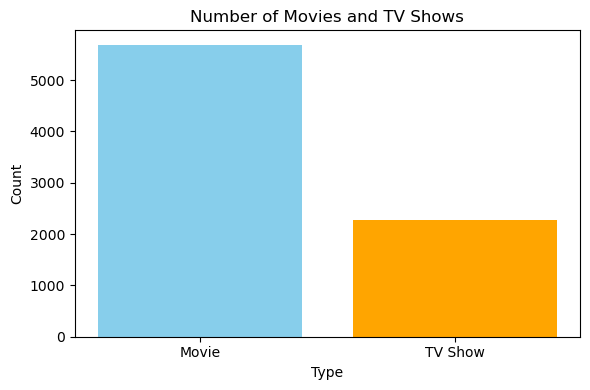

In [7]:
type_count = df['type'].value_counts()

print(type_count)
plt.figure(figsize=(6, 4))
plt.bar(type_count.index, type_count.values, color=['skyblue', 'orange'])
plt.title('Number of Movies and TV Shows')
plt.xlabel('Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

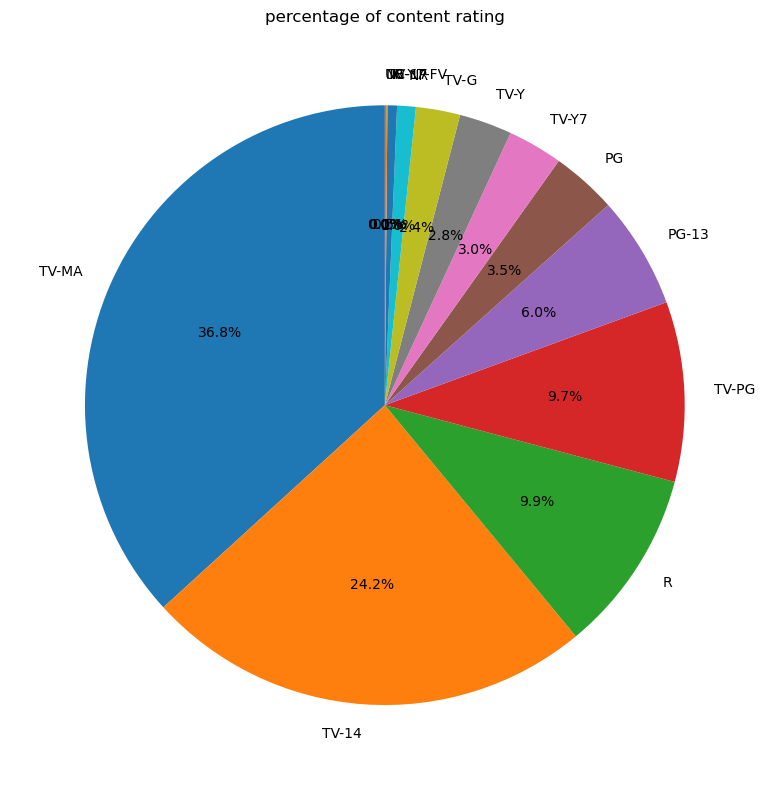

In [18]:
rating_count = df['rating'].value_counts()
plt.figure(figsize=(10,8))
plt.pie(rating_count,labels=rating_count.index,autopct='%1.1f%%',startangle=90)
plt.title('percentage of content rating')
plt.tight_layout()
plt.show()

C:\Users\dgajj\AppData\Local\Temp\ipykernel_31596\875986599.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  movie_df['duration_int'] = movie_df['duration'].str.replace('min','').astype(int)


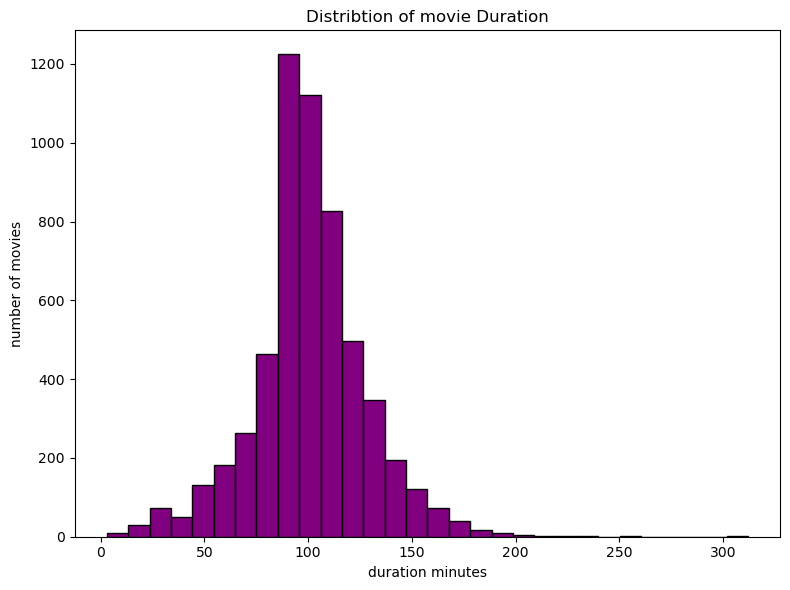

In [22]:
movie_df = df[df['type'] == 'Movie']
movie_df['duration_int'] = movie_df['duration'].str.replace('min','').astype(int)

plt.figure(figsize=(8,6))
plt.hist(movie_df['duration_int'],bins=30,color='purple',edgecolor='black')
plt.title('Distribtion of movie Duration')
plt.xlabel('duration minutes')
plt.ylabel('number of movies')
plt.tight_layout()
plt.show()

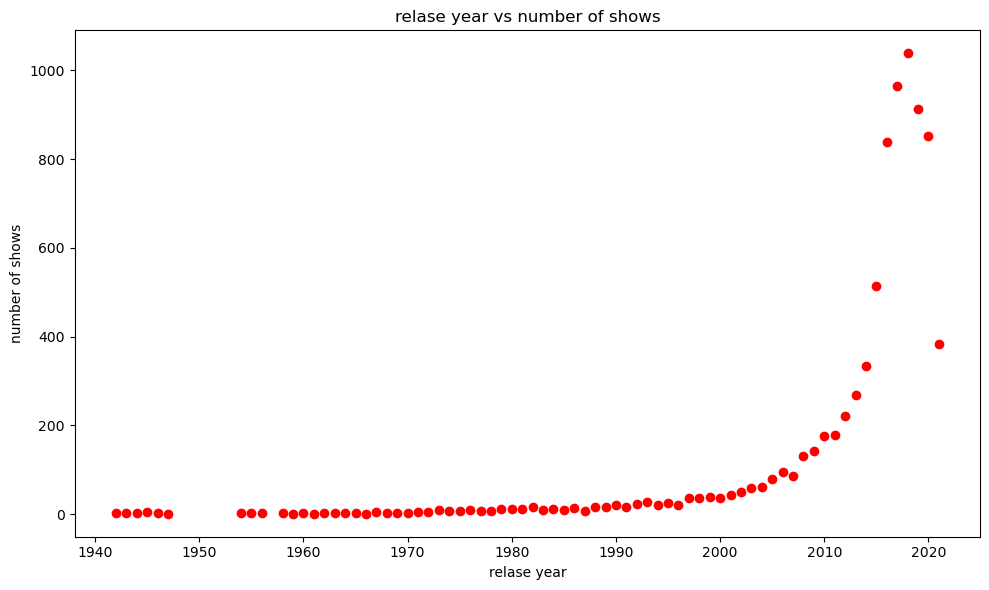

release_year
2018    1038
2017     965
2019     913
2020     852
2016     838
Name: count, dtype: int64

In [28]:
#scatter plot
relase_count = df['release_year'].value_counts()
plt.figure(figsize=(10,6))
plt.scatter(relase_count.index,relase_count.values,color='red')
plt.title('relase year vs number of shows')
plt.xlabel('relase year')
plt.ylabel('number of shows')
plt.tight_layout()
plt.show()
relase_count.head()


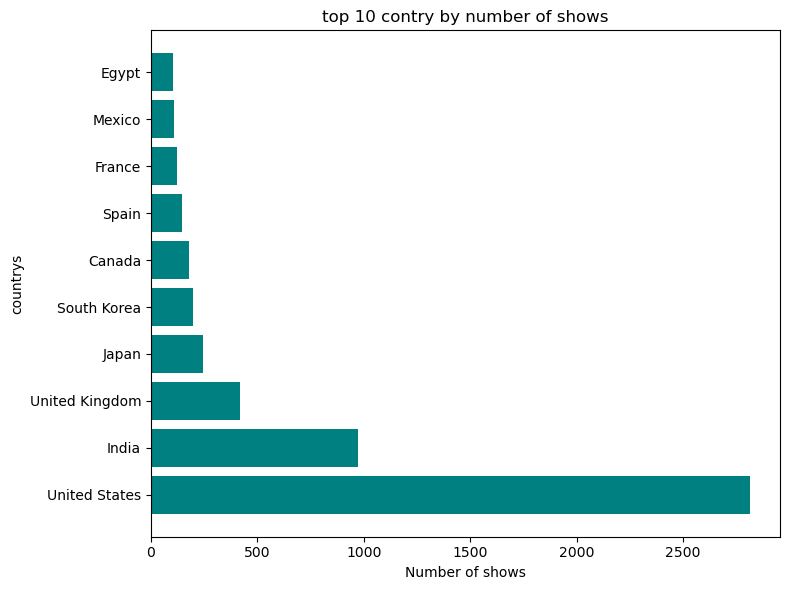

In [30]:
country_counts= df['country'].value_counts().head(10)
plt.figure(figsize=(8,6))
plt.barh(country_counts.index,country_counts.values,color='teal')
plt.title('top 10 contry by number of shows')
plt.xlabel('Number of shows')
plt.ylabel('countrys')
plt.tight_layout()
plt.show()

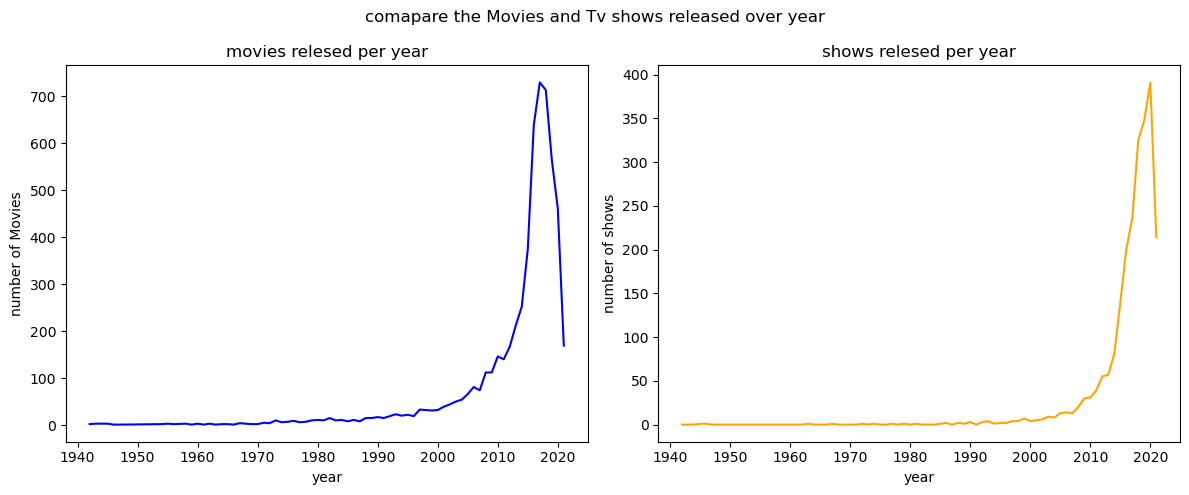

In [35]:
content_by_user = df.groupby(['release_year','type']).size().unstack().fillna(0)
fig,ax = plt.subplots(1,2,figsize=(12,5))

ax[0].plot(content_by_user.index,content_by_user['Movie'],color='blue')
ax[0].set_title('movies relesed per year')
ax[0].set_xlabel('year')
ax[0].set_ylabel('number of Movies')

ax[1].plot(content_by_user.index,content_by_user['TV Show'],color='orange')
ax[1].set_title('shows relesed per year')
ax[1].set_xlabel('year')
ax[1].set_ylabel('number of shows')

fig.suptitle('comapare the Movies and Tv shows released over year')

plt.tight_layout()
plt.show()